# Задача 7. Векторизация вычислений

**Цель:** заменить хранение фотонов в Python-списках на массивы `numpy.ndarray`, переписать генерацию и распространение фотонов, а также расчёт числа фотоэлектронов так, чтобы основные операции выполнялись сразу над массивами. Затем оценить выигрыш во времени по сравнению с обработкой каждого фотона в цикле.

Векторизованная реализация будет сопоставлена со скалярной реализацией, выполняющей те же физические действия. Для воспроизводимости обе реализации используют одинаковую последовательность псевдослучайных чисел.

> **Ограничение исходных данных.** В условии на скриншоте не приведены конкретная геометрия детектора и код предыдущих заданий. Поэтому ниже используется прозрачная демонстрационная модель цилиндрического сцинтиллятора. Геометрические и оптические параметры собраны в одной ячейке и должны быть заменены параметрами вашего проекта при интеграции.

## 1. Физическая модель и допущения

Рассматривается однородный цилиндрический сцинтиллятор радиуса $R$ и высоты $H$. Точечное событие с энерговыделением $E$ происходит в точке $(x_0,y_0,z_0)$.

1. Число рождённых фотонов флуктуирует по закону Пуассона:
   $$N_\gamma\sim\operatorname{Pois}(Y_\gamma E),$$
   где $Y_\gamma$ — световыход в фотонах/МэВ.
2. Фотоны испускаются из точки события изотропно. Для изотропного распределения $\cos\theta$ равномерно распределён на $[-1,1]$, а азимут $\varphi$ — на $[0,2\pi)$:
   $$u_x=\sqrt{1-\cos^2\theta}\cos\varphi,\quad
     u_y=\sqrt{1-\cos^2\theta}\sin\varphi,\quad
     u_z=\cos\theta.$$
3. Фотоны распространяются прямолинейно. Боковая поверхность и верхний торец считаются поглощающими; фотоприёмник полностью покрывает нижний торец. Учитываются только фотоны, первой пересекающие нижний торец.
4. Вероятность пережить поглощение на пути $s$ задаётся законом Бугера–Ламберта:
   $$P_{\rm surv}(s)=\exp(-s/\lambda),$$
   где для согласования с задачей 6 используется $\lambda=8$ м.
5. Для дошедшего до фотоприёмника фотона фотоэлектрон регистрируется с вероятностью PDE (photon detection efficiency).

Отражение от стенок, рассеяние, зависимость PDE от длины волны, флуктуации времени пролёта и электронный шум не учитываются. Это намеренно упрощённая модель для сравнения вычислительных подходов, а не полная оптическая модель реального детектора.

## 2. Импорт библиотек и параметры

Параметры геометрии и детектора ниже — **демонстрационные**, а не извлечённые из репозитория. Для переноса в основной проект достаточно изменить этот блок и, при необходимости, геометрию в функциях пересечения траекторий.

In [1]:
import math
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Энерговыделение и световыход
DEPOSITED_ENERGY_MEV = 1.0
PHOTON_YIELD_PER_MEV = 10_000.0  # демонстрационное значение, фотонов/МэВ

# Геометрия цилиндрического сцинтиллятора (демонстрационные значения)
DETECTOR_RADIUS_M = 0.05
DETECTOR_HEIGHT_M = 0.10
SOURCE_POSITION_M = (0.0, 0.0, DETECTOR_HEIGHT_M / 2)

# Оптика и фотоприёмник
ATTENUATION_LENGTH_M = 8.0  # значение из задачи 6
PHOTON_DETECTION_EFFICIENCY = 0.25

RANDOM_SEED = 20261102

assert DEPOSITED_ENERGY_MEV > 0
assert PHOTON_YIELD_PER_MEV > 0
assert DETECTOR_RADIUS_M > 0 and DETECTOR_HEIGHT_M > 0
assert ATTENUATION_LENGTH_M > 0
assert 0 <= PHOTON_DETECTION_EFFICIENCY <= 1

mean_photon_count = PHOTON_YIELD_PER_MEV * DEPOSITED_ENERGY_MEV
print(f"Среднее число фотонов на событие: {mean_photon_count:,.0f}")
print(f"Цилиндр: R = {DETECTOR_RADIUS_M:.3f} м, H = {DETECTOR_HEIGHT_M:.3f} м")
print(f"Положение источника: {SOURCE_POSITION_M} м")
print(f"Длина затухания: {ATTENUATION_LENGTH_M:.1f} м; PDE = {PHOTON_DETECTION_EFFICIENCY:.2f}")

Среднее число фотонов на событие: 10,000
Цилиндр: R = 0.050 м, H = 0.100 м
Положение источника: (0.0, 0.0, 0.05) м
Длина затухания: 8.0 м; PDE = 0.25


## 3. Формат данных: один массив на все фотоны события

В векторизованной версии используется двумерный массив формы `(N_photons, 6)`. Каждая строка соответствует одному фотону, столбцы содержат координаты точки рождения и компоненты единичного вектора направления:

| Индекс | Содержимое |
|---:|---|
| 0, 1, 2 | $x$, $y$, $z$ — координаты рождения, м |
| 3, 4, 5 | $u_x$, $u_y$, $u_z$ — компоненты направления |

Вместо списка объектов Python массив хранит однородные числовые данные в компактном блоке памяти. Это позволяет выполнять арифметические операции над множеством фотонов за один вызов NumPy.

## 4. Скалярная реализация: обработка фотонов по одному

Эта реализация играет роль контрольного варианта. Для каждого фотона отдельно генерируется направление, вычисляется пересечение с границами детектора, разыгрывается поглощение и проверяется регистрация фотоэлектрона.

In [2]:
def validate_source_position(source_xyz, radius_m, height_m):
    """Проверить, что точка события находится внутри цилиндра."""
    source = np.asarray(source_xyz, dtype=float)
    if source.shape != (3,) or not np.all(np.isfinite(source)):
        raise ValueError("source_xyz должен содержать три конечные координаты")
    x0, y0, z0 = source
    if x0*x0 + y0*y0 >= radius_m*radius_m or not (0.0 < z0 < height_m):
        raise ValueError("Источник должен находиться строго внутри цилиндра")
    return tuple(float(v) for v in source)


def generate_photons_scalar(n_photons, source_xyz, rng):
    """Сгенерировать фотоны по одному; вернуть список кортежей (x,y,z,ux,uy,uz)."""
    if not isinstance(n_photons, (int, np.integer)) or n_photons < 0:
        raise ValueError("n_photons должен быть неотрицательным целым")
    x0, y0, z0 = source_xyz
    photons = []
    for _ in range(n_photons):
        # Два независимых равномерных числа задают изотропное направление.
        cos_theta = 2.0 * rng.random() - 1.0
        phi = 2.0 * math.pi * rng.random()
        sin_theta = math.sqrt(max(0.0, 1.0 - cos_theta*cos_theta))
        ux = sin_theta * math.cos(phi)
        uy = sin_theta * math.sin(phi)
        uz = cos_theta
        photons.append((x0, y0, z0, ux, uy, uz))
    return photons


def _first_boundary_scalar(photon, radius_m, height_m):
    """Найти первую границу, которую пересечёт один фотон."""
    x, y, z, ux, uy, uz = map(float, photon)
    inf = math.inf

    # Верхний и нижний торцы.
    t_top = (height_m - z) / uz if uz > 0.0 else inf
    t_bottom = -z / uz if uz < 0.0 else inf

    # Боковая поверхность: x(t)^2 + y(t)^2 = R^2.
    a = ux*ux + uy*uy
    if a > 1e-15:
        b = 2.0 * (x*ux + y*uy)
        c = x*x + y*y - radius_m*radius_m
        discriminant = max(0.0, b*b - 4.0*a*c)
        t_side = (-b + math.sqrt(discriminant)) / (2.0*a)
    else:
        t_side = inf

    distance = min(t_top, t_bottom, t_side)
    hit_sensor = (t_bottom <= t_top) and (t_bottom <= t_side)
    return distance, hit_sensor


def propagate_photons_scalar(photons, rng, radius_m, height_m, attenuation_length_m):
    """Проследить отдельные фотоны и разыграть поглощение на пути.

    Возвращает список записей (hit_sensor, path_length, survived).
    Случайное число разыгрывается для каждого фотона, в том числе не попавшего
    на фотоприёмник: это обеспечивает совпадение последовательности RNG
    со векторизованной реализацией.
    """
    states = []
    for photon in photons:
        distance, hit_sensor = _first_boundary_scalar(photon, radius_m, height_m)
        transmission = math.exp(-distance / attenuation_length_m) if hit_sensor else 0.0
        random_value = rng.random()
        survived = bool(hit_sensor and (random_value < transmission))
        states.append((hit_sensor, distance, survived))
    return states


def count_photoelectrons_scalar(states, rng, pde):
    """Разыграть регистрацию фотоэлектронов по одному фотону."""
    n_photoelectrons = 0
    for _, _, survived in states:
        random_value = rng.random()
        if survived and random_value < pde:
            n_photoelectrons += 1
    return n_photoelectrons

print("Скалярная реализация определена.")

Скалярная реализация определена.


## 5. Векторизованная реализация NumPy

Здесь те же операции выполняются над массивами целиком. В частности, пересечение траекторий с цилиндром рассчитывается через маски `numpy`, а не через цикл по фотонам. Циклы по отдельным фотонам в этих функциях отсутствуют.

In [3]:
def generate_photons_numpy(n_photons, source_xyz, rng):
    """Векторизованная генерация: ndarray формы (N, 6)."""
    if not isinstance(n_photons, (int, np.integer)) or n_photons < 0:
        raise ValueError("n_photons должен быть неотрицательным целым")
    x0, y0, z0 = source_xyz

    random_values = rng.random((n_photons, 2))
    cos_theta = 2.0 * random_values[:, 0] - 1.0
    phi = 2.0 * np.pi * random_values[:, 1]
    sin_theta = np.sqrt(np.maximum(0.0, 1.0 - cos_theta**2))

    photons = np.empty((n_photons, 6), dtype=np.float64)
    photons[:, 0] = x0
    photons[:, 1] = y0
    photons[:, 2] = z0
    photons[:, 3] = sin_theta * np.cos(phi)
    photons[:, 4] = sin_theta * np.sin(phi)
    photons[:, 5] = cos_theta
    return photons


def propagate_photons_numpy(photons, rng, radius_m, height_m, attenuation_length_m):
    """Векторизованное пересечение цилиндра и розыгрыш оптического поглощения."""
    photons = np.asarray(photons, dtype=np.float64)
    if photons.ndim != 2 or photons.shape[1] != 6:
        raise ValueError("photons должен иметь форму (N, 6)")
    if radius_m <= 0 or height_m <= 0 or attenuation_length_m <= 0:
        raise ValueError("Размеры детектора и длина затухания должны быть положительными")

    x, y, z = photons[:, 0], photons[:, 1], photons[:, 2]
    ux, uy, uz = photons[:, 3], photons[:, 4], photons[:, 5]
    n = photons.shape[0]
    inf = np.inf

    t_top = np.full(n, inf)
    upward = uz > 0.0
    t_top[upward] = (height_m - z[upward]) / uz[upward]

    t_bottom = np.full(n, inf)
    downward = uz < 0.0
    t_bottom[downward] = -z[downward] / uz[downward]

    a = ux*ux + uy*uy
    t_side = np.full(n, inf)
    non_vertical = a > 1e-15
    b = 2.0 * (x*ux + y*uy)
    c = x*x + y*y - radius_m*radius_m
    discriminant = np.maximum(0.0, b*b - 4.0*a*c)
    t_side[non_vertical] = (
        -b[non_vertical] + np.sqrt(discriminant[non_vertical])
    ) / (2.0*a[non_vertical])

    distance = np.minimum(np.minimum(t_top, t_bottom), t_side)
    hit_sensor = (t_bottom <= t_top) & (t_bottom <= t_side)
    transmission = np.zeros(n, dtype=np.float64)
    transmission[hit_sensor] = np.exp(-distance[hit_sensor] / attenuation_length_m)

    # Для всех фотонов генерируем по одному случайному числу, чтобы сохранить
    # ту же последовательность RNG, что и в скалярной реализации.
    survived = hit_sensor & (rng.random(n) < transmission)
    return {
        "hit_sensor": hit_sensor,
        "distance": distance,
        "survived": survived,
    }


def count_photoelectrons_numpy(states, rng, pde):
    """Векторизованный розыгрыш фотоэлектронов и подсчёт зарегистрированных PE."""
    if not 0.0 <= pde <= 1.0:
        raise ValueError("pde должен лежать в диапазоне [0, 1]")
    survived = np.asarray(states["survived"], dtype=bool)
    detected = survived & (rng.random(survived.size) < pde)
    return int(np.count_nonzero(detected))

print("Векторизованная реализация определена.")

Векторизованная реализация определена.


## 6. Проверка эквивалентности двух реализаций

Сравним обе реализации при одинаковом начальном состоянии генератора случайных чисел. Сначала они должны породить одинаковые направления фотонов; затем — одинаковые результаты геометрического трассирования, поглощения и регистрации PE. Это более строгая проверка, чем сравнение только средних значений.

In [4]:
N_CHECK = 20_000
seed_check = 314159

rng_scalar = np.random.default_rng(seed_check)
photons_scalar = generate_photons_scalar(N_CHECK, SOURCE_POSITION_M, rng_scalar)
states_scalar = propagate_photons_scalar(
    photons_scalar, rng_scalar, DETECTOR_RADIUS_M, DETECTOR_HEIGHT_M, ATTENUATION_LENGTH_M
)
pe_scalar = count_photoelectrons_scalar(
    states_scalar, rng_scalar, PHOTON_DETECTION_EFFICIENCY
)

rng_numpy = np.random.default_rng(seed_check)
photons_numpy = generate_photons_numpy(N_CHECK, SOURCE_POSITION_M, rng_numpy)
states_numpy = propagate_photons_numpy(
    photons_numpy, rng_numpy, DETECTOR_RADIUS_M, DETECTOR_HEIGHT_M, ATTENUATION_LENGTH_M
)
pe_numpy = count_photoelectrons_numpy(
    states_numpy, rng_numpy, PHOTON_DETECTION_EFFICIENCY
)

scalar_array = np.asarray(photons_scalar, dtype=float)
print("Совпадение фотонных массивов:", np.allclose(scalar_array, photons_numpy, rtol=0, atol=1e-14))
print("Максимальное отклонение направлений:", np.max(np.abs(scalar_array[:, 3:] - photons_numpy[:, 3:])))
print("Совпадение маски попадания на датчик:", np.array_equal(
    np.array([s[0] for s in states_scalar]), states_numpy["hit_sensor"]
))
print("Совпадение маски выживших фотонов:", np.array_equal(
    np.array([s[2] for s in states_scalar]), states_numpy["survived"]
))
print(f"Число фотоэлектронов: scalar = {pe_scalar}, NumPy = {pe_numpy}")

assert np.allclose(scalar_array, photons_numpy, rtol=0, atol=1e-14)
assert np.array_equal(np.array([s[0] for s in states_scalar]), states_numpy["hit_sensor"])
assert np.array_equal(np.array([s[2] for s in states_scalar]), states_numpy["survived"])
assert pe_scalar == pe_numpy
print("\nОбе реализации дают идентичный результат для заданного seed.")

Совпадение фотонных массивов: True
Максимальное отклонение направлений: 0.0
Совпадение маски попадания на датчик: True
Совпадение маски выживших фотонов: True
Число фотоэлектронов: scalar = 725, NumPy = 725

Обе реализации дают идентичный результат для заданного seed.


## 7. Одно моделируемое событие и статистика прохождения фотонов

Для одного события с энерговыделением $1$ МэВ число исходных фотонов генерируется по распределению Пуассона. Далее последовательно оцениваются геометрическая эффективность, потери на оптическом пути и число PE.

In [5]:
def simulate_event_numpy(energy_mev, seed=RANDOM_SEED):
    """Полное моделирование одного события в векторизованной реализации."""
    if not np.isfinite(energy_mev) or energy_mev < 0:
        raise ValueError("energy_mev должен быть конечным и неотрицательным")
    rng = np.random.default_rng(seed)
    n_photons = int(rng.poisson(PHOTON_YIELD_PER_MEV * energy_mev))
    photons = generate_photons_numpy(n_photons, SOURCE_POSITION_M, rng)
    states = propagate_photons_numpy(
        photons, rng, DETECTOR_RADIUS_M, DETECTOR_HEIGHT_M, ATTENUATION_LENGTH_M
    )
    n_pe = count_photoelectrons_numpy(states, rng, PHOTON_DETECTION_EFFICIENCY)
    return {
        "n_photons": n_photons,
        "n_hit_sensor": int(np.count_nonzero(states["hit_sensor"])),
        "n_survived": int(np.count_nonzero(states["survived"])),
        "n_photoelectrons": n_pe,
        "photons": photons,
        "states": states,
    }


event_result = simulate_event_numpy(DEPOSITED_ENERGY_MEV)
event_summary = pd.DataFrame([
    ("Рождённые фотоны", event_result["n_photons"]),
    ("Дошли до нижнего фотоприёмника", event_result["n_hit_sensor"]),
    ("Пережили оптическое поглощение", event_result["n_survived"]),
    ("Зарегистрированные фотоэлектроны", event_result["n_photoelectrons"]),
], columns=["Стадия", "Количество"])
display(event_summary)

print(f"Геометрическая эффективность: {event_result['n_hit_sensor'] / event_result['n_photons']:.4f}")
print(f"Доля выживших среди попавших на датчик: {event_result['n_survived'] / max(1, event_result['n_hit_sensor']):.4f}")

,Стадия,Количество
0,Рождённые фотоны,10052
1,Дошли до нижнего фотоприёмника,1466
2,Пережили оптическое поглощение,1452
3,Зарегистрированные фотоэлектроны,372


Геометрическая эффективность: 0.1458
Доля выживших среди попавших на датчик: 0.9905


### Визуализация направления и попаданий

На левой панели показано распределение направлений фотонов в проекции $x$–$z$ (для наглядности отображается подвыборка). На правой — точки попадания на нижнюю плоскость фотоприёмника.

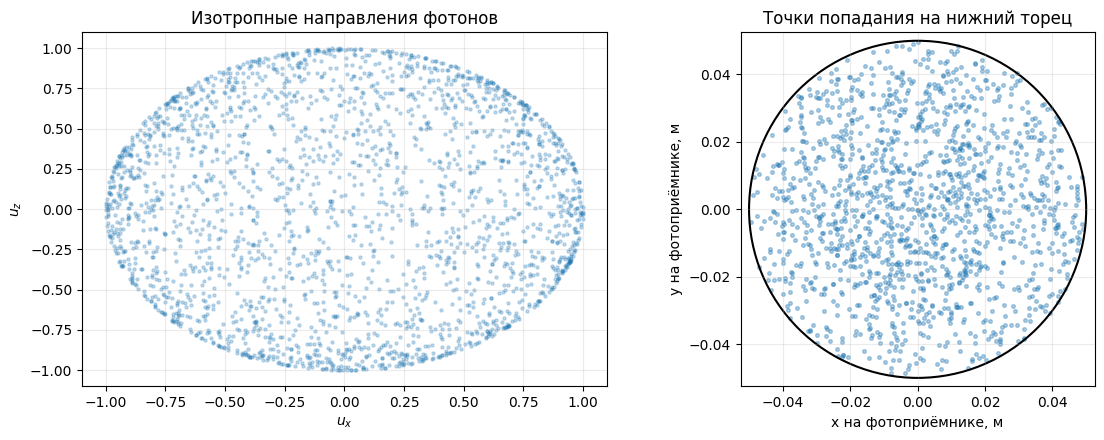

In [6]:
photons = event_result["photons"]
hit = event_result["states"]["hit_sensor"]
distance = event_result["states"]["distance"]

# Координаты пересечения нижней плоскости для фотонов, попавших на фотоприёмник.
hit_photons = photons[hit]
t_hit = distance[hit]
impact_x = hit_photons[:, 0] + t_hit * hit_photons[:, 3]
impact_y = hit_photons[:, 1] + t_hit * hit_photons[:, 4]

rng_plot = np.random.default_rng(12345)
plot_n = min(2500, len(photons))
plot_indices = rng_plot.choice(len(photons), size=plot_n, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(photons[plot_indices, 3], photons[plot_indices, 5], s=5, alpha=0.25)
axes[0].set_xlabel(r"$u_x$")
axes[0].set_ylabel(r"$u_z$")
axes[0].set_title("Изотропные направления фотонов")
axes[0].grid(alpha=0.25)

axes[1].scatter(impact_x, impact_y, s=7, alpha=0.35)
axes[1].add_patch(plt.Circle((0, 0), DETECTOR_RADIUS_M, fill=False, linewidth=1.5))
axes[1].set_aspect("equal", adjustable="box")
axes[1].set_xlim(-1.05*DETECTOR_RADIUS_M, 1.05*DETECTOR_RADIUS_M)
axes[1].set_ylim(-1.05*DETECTOR_RADIUS_M, 1.05*DETECTOR_RADIUS_M)
axes[1].set_xlabel("x на фотоприёмнике, м")
axes[1].set_ylabel("y на фотоприёмнике, м")
axes[1].set_title("Точки попадания на нижний торец")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Оценка выигрыша во времени

Сравним время выполнения полного цикла для фиксированного числа фотонов:

1. генерация направлений;
2. трассировка до первой поверхности цилиндра и розыгрыш оптического поглощения;
3. розыгрыш регистрации фотоэлектронов.

В обеих реализациях используется один и тот же seed. Поэтому при одинаковом числе фотонов результат должен совпадать, а измерение времени не смешивается с различиями в случайных выборках. Замеры повторяются несколько раз; в таблице приводится медиана. Время зависит от процессора, версии Python и NumPy.

In [7]:
def run_pipeline_scalar(n_photons, seed):
    rng = np.random.default_rng(seed)
    photons = generate_photons_scalar(n_photons, SOURCE_POSITION_M, rng)
    states = propagate_photons_scalar(
        photons, rng, DETECTOR_RADIUS_M, DETECTOR_HEIGHT_M, ATTENUATION_LENGTH_M
    )
    return count_photoelectrons_scalar(states, rng, PHOTON_DETECTION_EFFICIENCY)


def run_pipeline_numpy(n_photons, seed):
    rng = np.random.default_rng(seed)
    photons = generate_photons_numpy(n_photons, SOURCE_POSITION_M, rng)
    states = propagate_photons_numpy(
        photons, rng, DETECTOR_RADIUS_M, DETECTOR_HEIGHT_M, ATTENUATION_LENGTH_M
    )
    return count_photoelectrons_numpy(states, rng, PHOTON_DETECTION_EFFICIENCY)


def median_runtime(function, repeats=3):
    """Медиана wall-clock времени одного вызова функции."""
    samples = []
    for _ in range(repeats):
        start = time.perf_counter()
        function()
        samples.append(time.perf_counter() - start)
    return float(np.median(samples))


photon_counts = [1_000, 5_000, 20_000, 50_000]
benchmark_rows = []

for n in photon_counts:
    # Проверяем одинаковый результат до измерения времени.
    pe_s = run_pipeline_scalar(n, seed=777)
    pe_v = run_pipeline_numpy(n, seed=777)
    assert pe_s == pe_v, f"Результаты различаются при N={n}"

    t_scalar = median_runtime(lambda: run_pipeline_scalar(n, seed=777), repeats=3)
    t_numpy = median_runtime(lambda: run_pipeline_numpy(n, seed=777), repeats=3)
    benchmark_rows.append({
        "Число фотонов": n,
        "Скалярная версия, с": t_scalar,
        "NumPy, с": t_numpy,
        "Ускорение": t_scalar / t_numpy if t_numpy > 0 else np.nan,
        "N_PE (обе версии)": pe_s,
    })

benchmark = pd.DataFrame(benchmark_rows)
display(benchmark.round({"Скалярная версия, с": 6, "NumPy, с": 6, "Ускорение": 2}))

,Число фотонов,"Скалярная версия, с","NumPy, с",Ускорение,N_PE (обе версии)
0,1000,0.002048,0.000286,7.17,38
1,5000,0.011614,0.000594,19.55,160
2,20000,0.049395,0.002121,23.29,737
3,50000,0.107534,0.006884,15.62,1778


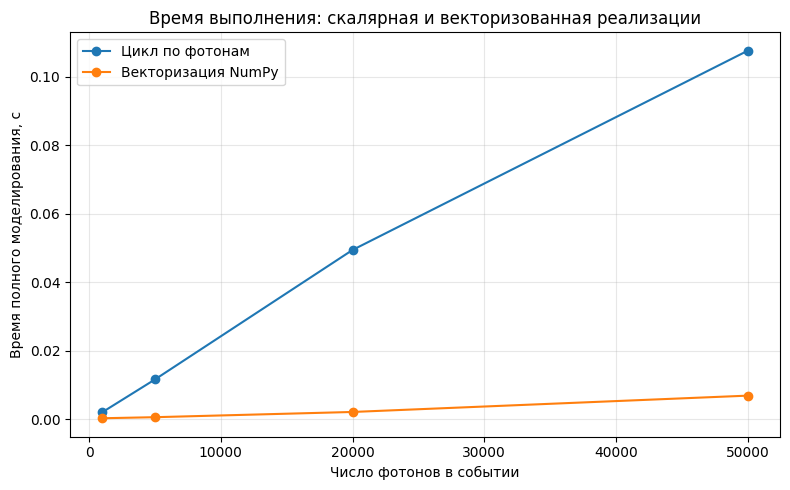

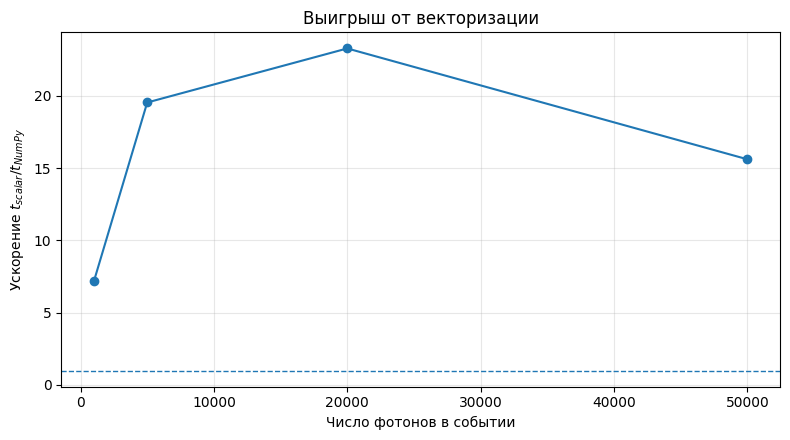

Медианное ускорение по выбранным размерам: 17.59x


In [8]:
plt.figure(figsize=(8, 5))
plt.plot(benchmark["Число фотонов"], benchmark["Скалярная версия, с"], marker="o", label="Цикл по фотонам")
plt.plot(benchmark["Число фотонов"], benchmark["NumPy, с"], marker="o", label="Векторизация NumPy")
plt.xlabel("Число фотонов в событии")
plt.ylabel("Время полного моделирования, с")
plt.title("Время выполнения: скалярная и векторизованная реализации")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4.5))
plt.plot(benchmark["Число фотонов"], benchmark["Ускорение"], marker="o")
plt.axhline(1.0, linestyle="--", linewidth=1)
plt.xlabel("Число фотонов в событии")
plt.ylabel("Ускорение $t_{scalar}/t_{NumPy}$")
plt.title("Выигрыш от векторизации")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Медианное ускорение по выбранным размерам: {benchmark['Ускорение'].median():.2f}x")

## 9. Автоматические тесты (`pytest`)

Тесты фиксируют ключевые свойства реализации: размер и тип массива, нормировку направлений, корректность геометрических масок и совпадение скалярного и векторизованного вариантов. Используются параметризация и fixture — инструменты, рассмотренные в лекции 4.

In [9]:
import sys
import types
import tempfile
import textwrap
from pathlib import Path
import pytest

_model = types.ModuleType("vectorization_model_for_pytest")
for _name in [
    "generate_photons_scalar", "generate_photons_numpy",
    "propagate_photons_scalar", "propagate_photons_numpy",
    "count_photoelectrons_scalar", "count_photoelectrons_numpy",
    "_first_boundary_scalar", "validate_source_position",
]:
    setattr(_model, _name, globals()[_name])
sys.modules[_model.__name__] = _model

test_source = r'''import numpy as np
import pytest
from vectorization_model_for_pytest import (
    generate_photons_scalar, generate_photons_numpy,
    propagate_photons_scalar, propagate_photons_numpy,
    count_photoelectrons_scalar, count_photoelectrons_numpy,
    validate_source_position,
)

@pytest.fixture
def geometry():
    return {"source": (0.0, 0.0, 0.05), "radius": 0.05, "height": 0.10, "attenuation": 8.0}

@pytest.mark.parametrize("n", [0, 1, 100, 5000])
def test_numpy_shape_and_direction_norm(n, geometry):
    photons = generate_photons_numpy(n, geometry["source"], np.random.default_rng(10))
    assert photons.shape == (n, 6)
    assert photons.dtype == np.float64
    if n:
        assert np.allclose(np.linalg.norm(photons[:, 3:], axis=1), 1.0, atol=1e-12)

@pytest.mark.parametrize("n", [1, 10, 1000])
def test_scalar_and_numpy_generation_match(n, geometry):
    a = generate_photons_scalar(n, geometry["source"], np.random.default_rng(123))
    b = generate_photons_numpy(n, geometry["source"], np.random.default_rng(123))
    assert np.allclose(np.asarray(a), b, rtol=0, atol=1e-14)

@pytest.mark.parametrize("n", [1, 100, 2000])
def test_scalar_and_numpy_propagation_match(n, geometry):
    photons = generate_photons_numpy(n, geometry["source"], np.random.default_rng(321))
    scalar_states = propagate_photons_scalar(
        [tuple(row) for row in photons], np.random.default_rng(456),
        geometry["radius"], geometry["height"], geometry["attenuation"]
    )
    numpy_states = propagate_photons_numpy(
        photons, np.random.default_rng(456),
        geometry["radius"], geometry["height"], geometry["attenuation"]
    )
    assert np.array_equal(np.array([x[0] for x in scalar_states]), numpy_states["hit_sensor"])
    assert np.allclose(np.array([x[1] for x in scalar_states]), numpy_states["distance"])
    assert np.array_equal(np.array([x[2] for x in scalar_states]), numpy_states["survived"])

def test_photoelectron_count_matches(geometry):
    photons = generate_photons_numpy(3000, geometry["source"], np.random.default_rng(1))
    states_s = propagate_photons_scalar(
        [tuple(row) for row in photons], np.random.default_rng(2), 0.05, 0.10, 8.0
    )
    states_v = propagate_photons_numpy(photons, np.random.default_rng(2), 0.05, 0.10, 8.0)
    pe_s = count_photoelectrons_scalar(states_s, np.random.default_rng(3), 0.25)
    pe_v = count_photoelectrons_numpy(states_v, np.random.default_rng(3), 0.25)
    assert pe_s == pe_v

def test_zero_pde_gives_zero_photoelectrons():
    states = [(True, 0.1, True), (True, 0.2, False)]
    assert count_photoelectrons_scalar(states, np.random.default_rng(4), 0.0) == 0
    vstates = {"survived": np.array([True, False])}
    assert count_photoelectrons_numpy(vstates, np.random.default_rng(4), 0.0) == 0

def test_source_outside_detector_raises():
    with pytest.raises(ValueError):
        validate_source_position((0.1, 0.0, 0.05), 0.05, 0.10)
'''

with tempfile.TemporaryDirectory() as tmp_dir:
    test_file = Path(tmp_dir) / "test_vectorization.py"
    test_file.write_text(textwrap.dedent(test_source), encoding="utf-8")
    pytest_result = pytest.main(["-q", str(test_file)])

assert pytest_result == pytest.ExitCode.OK, "Не все тесты пройдены"
print("Все автоматические тесты пройдены.")

.

.

.

.

.

.

... (6 outputs left out)

.

                                                            [100%]


13 passed in 0.10s


Все автоматические тесты пройдены.


## 10. Выводы

Векторизация затрагивает все три требуемые операции:

- **генерация:** координаты и направления всех фотонов хранятся в одном `numpy.ndarray`;
- **распространение:** расстояния до поверхностей цилиндра и маски попадания рассчитываются массивными операциями NumPy;
- **регистрация:** число фотоэлектронов получается подсчётом элементов булевой маски без Python-цикла по фотонам.

В таблице быстродействия приведено фактическое время выполнения на машине, где запускался ноутбук. Ускорение определяется отношением времени скалярной реализации к времени NumPy. При увеличении числа фотонов преимущество векторизации обычно становится заметнее, поскольку уменьшается относительная роль накладных расходов Python.

**Физическая оговорка:** абсолютное число фотоэлектронов в этом ноутбуке зависит от демонстрационных значений геометрии, световыхода и PDE. Основной результат задачи — совпадение двух алгоритмических реализаций и измерение их производительности при одинаковых входных данных.

## 11. Фиксация версии в Git

После переноса ноутбука в каталог `modeling/` его можно добавить в историю проекта:

```bash
git status
git add modeling/task7_vectorization.ipynb
git diff --staged
git commit -m "Add NumPy vectorization for photon simulation"
git push
```

Так ноутбук и результаты тестирования будут привязаны к конкретной версии проекта.